<h1 style="text-align:center;">Ejercicio Práctico</h1>

<p style="text-align:center;">05-11-2026</p>

<p style="text-align:center;">
  <img src="img/ITQ.png" width="500">
</p>

# 1. Práctica Académica

## Normalización y Estandarización de Datos en Inteligencia Artificial

**Nombre:** Nikolay Misael De La Cruz Melendres

**Asignatura:** Fundamentos de Machine Learning

**Docente:** Elvis David Pachacama Cabezas

**Tema:** Análisis y aplicación de técnicas de normalización y estandarización en conjuntos de datos para modelos de aprendizaje automático.

**Link Repositorio:** [NikolayDlc/fundamentosMachine](https://github.com/NikolayDlc/fundamentosMachine)

# 2. Objetivos

## Objetivo general

Aplicar técnicas de normalización y estandarización de datos mediante herramientas de Python para comprender su importancia en la preparación de datos para modelos de aprendizaje automático.

## Objetivos específicos

- Identificar las diferencias de escala entre variables numéricas.
- Aplicar la normalización Min-Max.
- Aplicar la estandarización Z-score.
- Analizar la importancia del preprocesamiento en Machine Learning.
- Comparar visualmente los datos originales, normalizados y estandarizados.

# 3. Antecedentes y fundamentación teórica

En el aprendizaje automático (Machine Learning), los algoritmos pueden verse afectados por las diferencias de escala entre las variables numéricas. Cuando algunas variables presentan valores mayores que otras, pueden influir más en los resultados de ciertos algoritmos, especialmente aquellos que utilizan distancias. 

Para tratar estas diferencias se emplean técnicas de preprocesamiento:

**Normalización Min-Max:** Transforma los valores de una característica a un rango determinado, generalmente entre 0 y 1.

**Estandarización Z-score:** Transforma los valores de una característica utilizando su media y desviación estándar, de manera que los datos estandarizados tengan aproximadamente media 0 y desviación estándar 1.

Estas técnicas son relevantes para algoritmos como:
- K vecinos más cercanos (KNN).
- Regresión logística.
- Redes neuronales.


# 4. Escenario de práctica

Una empresa de análisis de datos desea desarrollar modelos predictivos utilizando información de clientes. Sin embargo, se ha identificado que las variables presentan diferentes escalas, lo que puede afectar el rendimiento de determinados modelos de aprendizaje automático. Por este motivo, se solicita aplicar técnicas de preprocesamiento y limpieza de datos.

**Conjuntos de datos mencionados en la práctica:**

- **Dataset 1 (conceptual):** Iris Dataset.
- **Dataset 2 (aplicación real):** California Housing Dataset.

En el presente ejercicio se trabaja con el dataset Iris para analizar las características numéricas y aplicar técnicas de normalización y estandarización.


In [20]:
# Importación de librerías
import sys
import pandas as pd
import numpy as np
from sklearn.datasets import load_iris
import zipfile
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn import preprocessing
import os

In [21]:
# Configuramos el entorno de descarga de Kaggle

os.environ["KAGGLE_CONFIG_DIR"] = os.path.join(
    os.path.expanduser("~"),
    ".kaggle"
)

print("Carpeta de configuración:", os.environ["KAGGLE_CONFIG_DIR"])

Carpeta de configuración: C:\Users\ESTUDIANTE\.kaggle


In [22]:
# Creamos la carpeta dataset

os.makedirs("dataset", exist_ok=True)

print("Carpeta dataset preparada correctamente")

Carpeta dataset preparada correctamente


In [23]:
# Descargamos el dataset Iris desde Kaggle

!{sys.executable} -m kaggle datasets download -d uciml/iris

Dataset URL: https://www.kaggle.com/datasets/uciml/iris
License(s): CC0-1.0
iris.zip: Skipping, found more recently modified local copy (use --force to force download)


In [7]:
# Descomprimimos el archivo ZIP

with zipfile.ZipFile("iris.zip", "r") as zip_ref:
    zip_ref.extractall("dataset")

print("Archivos extraídos:", os.listdir("dataset"))

Archivos extraídos: ['database.sqlite', 'Iris.csv']


In [8]:
# Cargamos el conjunto de datos Iris

df = pd.read_csv("dataset/Iris.csv")

df.head()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


In [9]:
# Eliminamos la columna Id si existe,
# porque no representa una característica física de la flor.

if "Id" in df.columns:
    df = df.drop(columns=["Id"])

df.head()

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


In [10]:
# Mostramos información general del dataset

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   SepalLengthCm  150 non-null    float64
 1   SepalWidthCm   150 non-null    float64
 2   PetalLengthCm  150 non-null    float64
 3   PetalWidthCm   150 non-null    float64
 4   Species        150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 7.9 KB


In [11]:
# Verificamos cuántos valores nulos hay en cada columna

df.isnull().sum()

SepalLengthCm    0
SepalWidthCm     0
PetalLengthCm    0
PetalWidthCm     0
Species          0
dtype: int64

In [12]:
# Separamos los datos de entrada de la variable objetivo

X = df.drop(columns=["Species"])
y = df["Species"]

print("Características de entrada:")
print(X.columns)

print("\nVariable objetivo:")
print(y.name)

Características de entrada:
Index(['SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm'], dtype='str')

Variable objetivo:
Species


In [13]:
# Realizamos un análisis exploratorio
# de las características numéricas

X.describe()

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.054000,3.758667,1.198667
std,0.828066,0.433594,1.764420,0.763161
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000



## Conclusión del análisis exploratorio

Al observar las estadísticas descriptivas del dataset Iris, identificamos que las características numéricas presentan diferentes valores mínimos, máximos y rangos.

Por ejemplo:

- **PetalLengthCm:** presenta valores entre 1.0 y 6.9.
- **SepalWidthCm:** presenta valores entre 2.0 y 4.4.

Esto indica que las características no presentan exactamente las mismas escalas. En algoritmos como KNN, que utilizan distancias para comparar observaciones, estas diferencias pueden afectar la influencia de cada característica en el cálculo. Por esta razón, se estudiarán dos técnicas de preprocesamiento:

1. Normalización Min-Max.
2. Estandarización Z-score.

Estas transformaciones permiten comparar las características en escalas diferentes a las originales, pero no garantizan que todas tengan la misma importancia predictiva.


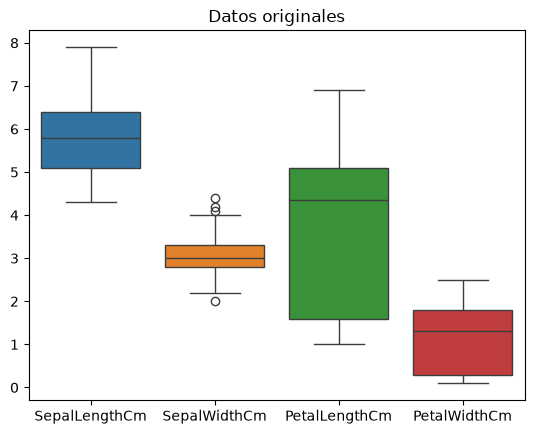

In [14]:
# Dibujamos un gráfico de cajas con los datos originales

sns.boxplot(data=X)

plt.title("Datos originales")
plt.show()

## Interpretación de los datos originales

El gráfico de cajas (boxplot) permite observar la distribución de los datos originales del dataset Iris.

A través de este gráfico podemos comparar:

- La mediana de cada característica.
- La dispersión de los datos.
- Los rangos de las diferentes variables.
- La presencia de posibles valores atípicos.

Se observa que algunas características presentan una mayor variabilidad que otras. Estas diferencias pueden afectar el comportamiento de algoritmos sensibles a las escalas de las variables. Por ello, se aplicarán técnicas de normalización y estandarización para comparar cómo cambia la representación numérica de las características.


In [15]:
# Normalizamos el conjunto de datos

normalizer = preprocessing.MinMaxScaler()

X_norm = normalizer.fit_transform(X)

X_norm = pd.DataFrame(
    X_norm,
    columns=X.columns
)

X_norm.head()

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
0,0.222222,0.625000,0.067797,0.041667
1,0.166667,0.416667,0.067797,0.041667
2,0.111111,0.500000,0.050847,0.041667
3,0.083333,0.458333,0.084746,0.041667
4,0.194444,0.666667,0.067797,0.041667


In [16]:
# Analizamos las estadísticas de los datos normalizados

X_norm.describe()

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
count,150.000000,150.000000,150.000000,150.000000
mean,0.428704,0.439167,0.467571,0.457778
std,0.230018,0.180664,0.299054,0.317984
min,0.000000,0.000000,0.000000,0.000000
25%,0.222222,0.333333,0.101695,0.083333
50%,0.416667,0.416667,0.567797,0.500000
75%,0.583333,0.541667,0.694915,0.708333
max,1.000000,1.000000,1.000000,1.000000


In [17]:
# Estandarización de las características

standarizer = preprocessing.StandardScaler()

X_std = standarizer.fit_transform(X)

X_std = pd.DataFrame(
    X_std,
    columns=X.columns
)

X_std.head()

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
0,-0.900681,1.032057,-1.341272,-1.312977
1,-1.143017,-0.124958,-1.341272,-1.312977
2,-1.385353,0.337848,-1.398138,-1.312977
3,-1.506521,0.106445,-1.284407,-1.312977
4,-1.021849,1.263460,-1.341272,-1.312977


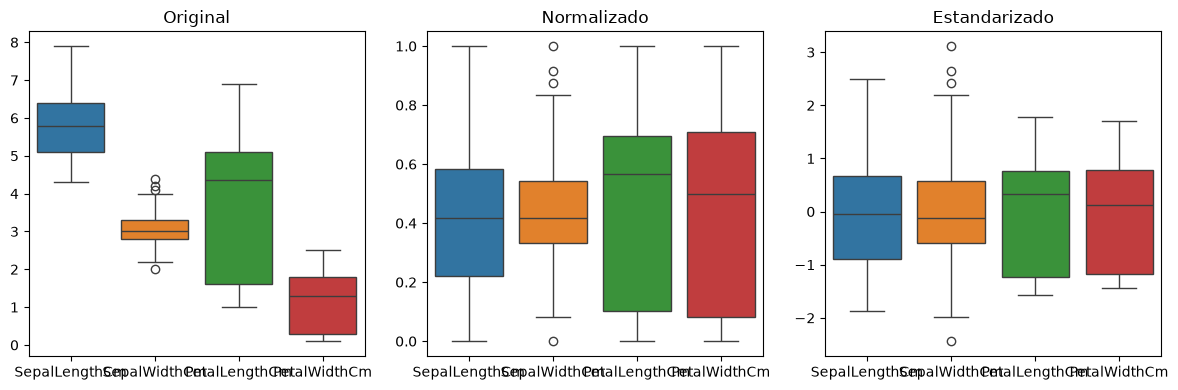

In [18]:
# Comparación visual de las tres versiones del dataset

plt.figure(figsize=(12, 4))

# Gráfico 1: Datos originales
plt.subplot(1, 3, 1)
sns.boxplot(data=X)
plt.title("Original")

# Gráfico 2: Datos normalizados
plt.subplot(1, 3, 2)
sns.boxplot(data=X_norm)
plt.title("Normalizado")

# Gráfico 3: Datos estandarizados
plt.subplot(1, 3, 3)
sns.boxplot(data=X_std)
plt.title("Estandarizado")

plt.tight_layout()
plt.show()